In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

from pathlib import Path

from skimage.transform import resize

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers


# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# Paths
DATA_ROOT = Path("../data/raw")
RESULTS_ROOT = Path("../results")

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

IMG_SIZE = 128

CLASS_NAMES = [
    "Glioma",
    "Meningioma",
    "Pituitary"
]

print("TensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)

TensorFlow: 2.21.0
Image size: 128


In [34]:
mat_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if p.name.lower() != "cvind.mat"
)

print(f"MAT files found: {len(mat_files)}")

MAT files found: 3064


========== DATASET LOADED ==========
Images      : 3064
Labels      : 3064
Patient IDs : 3064
Classes     : [1 2 3]
Unique patients: 233


In [35]:
def load_figshare_data(mat_files):
    images = []
    labels = []
    patient_ids = []

    for mat_file in mat_files:

        with h5py.File(mat_file, "r") as f:

            cjdata = f["cjdata"]

            image = np.asarray(
                cjdata["image"],
                dtype=np.float32
            )

            label = int(
                np.asarray(
                    cjdata["label"]
                ).squeeze()
            )

            pid_codes = np.asarray(
                cjdata["PID"]
            ).reshape(-1)

            patient_id = "".join(
                chr(int(code))
                for code in pid_codes
            )

            images.append(image)
            labels.append(label)
            patient_ids.append(patient_id)

    return (
        images,
        np.asarray(labels, dtype=np.int64),
        np.asarray(patient_ids)
    )


images, labels, patient_ids = load_figshare_data(
    mat_files
)

print("Images:", len(images))
print("Labels:", len(labels))
print("Patients:", len(np.unique(patient_ids)))

Images: 3064
Labels: 3064
Patients: 233


In [36]:
X_images = np.empty(
    (len(images), IMG_SIZE, IMG_SIZE),
    dtype=np.float32
)

for i, image in enumerate(images):

    resized = resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        anti_aliasing=True,
        preserve_range=True
    ).astype(np.float32)

    image_min = resized.min()
    image_max = resized.max()

    if image_max > image_min:
        resized = (
            resized - image_min
        ) / (
            image_max - image_min
        )
    else:
        resized = np.zeros_like(resized)

    X_images[i] = resized


y = labels.copy()

print("Input shape:", X_images.shape)
print("Label shape:", y.shape)

Input shape: (3064, 128, 128)
Label shape: (3064,)


In [37]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, test_idx = next(
    gss.split(
        X_images,
        y,
        groups=patient_ids
    )
)


X_train_images = X_images[train_idx]
X_test_images = X_images[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

pid_train = patient_ids[train_idx]
pid_test = patient_ids[test_idx]


print("Training samples:", len(X_train_images))
print("Testing samples :", len(X_test_images))

print(
    "Patient overlap:",
    len(
        set(pid_train) &
        set(pid_test)
    )
)

Training samples: 2452
Testing samples : 612
Patient overlap: 0


In [38]:
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

train_inner_idx, val_idx = next(
    gss_val.split(
        X_train_images,
        y_train,
        groups=pid_train
    )
)


X_train_final = X_train_images[
    train_inner_idx
]

X_val = X_train_images[
    val_idx
]

y_train_final = y_train[
    train_inner_idx
]

y_val = y_train[
    val_idx
]


print("Train:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_images.shape)

Train: (2051, 128, 128)
Validation: (401, 128, 128)
Test: (612, 128, 128)


In [39]:
X_train_flat = X_train_final.reshape(
    X_train_final.shape[0],
    -1
)

X_val_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_flat
)

X_val_scaled = scaler.transform(
    X_val_flat
)

X_test_scaled = scaler.transform(
    X_test_flat
)


print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (2051, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [40]:
y_train_ann = y_train_final - 1
y_val_ann = y_val - 1
y_test_ann = y_test - 1


classes = np.unique(y_train_ann)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ann
)

ann_class_weights = dict(
    zip(
        classes,
        class_weights_array
    )
)

print("Classes:", classes)
print("Class weights:", ann_class_weights)

Classes: [0 1 2]
Class weights: {0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [41]:
ann_v2 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.50),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.40),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v2"
)

ann_v2.summary()

Model: "Brain_Tumor_ANN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [42]:
ann_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [43]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [44]:
history_v2 = ann_v2.fit(
    X_train_scaled,
    y_train_ann,

    validation_data=(
        X_val_scaled,
        y_val_ann
    ),

    epochs=100,
    batch_size=32,

    class_weight=ann_class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5822 - loss: 0.9181
Epoch 1: val_loss improved from None to 0.58187, saving model to ..\results\best_ann_v2.keras

Epoch 1: finished saving model to ..\results\best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.5822 - loss: 0.9181 - val_accuracy: 0.8229 - val_loss: 0.5819 - learning_rate: 5.0000e-04
Epoch 2/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.7523 - loss: 0.6166
Epoch 2: val_loss improved from 0.58187 to 0.48734, saving model to ..\results\best_ann_v2.keras

Epoch 2: finished saving model to ..\results\best_ann_v2.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.7523 - loss: 0.6166 - val_accuracy: 0.8579 - val_loss: 0.4873 - learning_rate: 5.0000e-04
Epoch 3/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8240 - loss: 0.4979
Epoch 3: val_loss did not improve from 0.48734
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.8240 - loss: 0.4979 - val_accuracy

In [45]:
best_ann_v2 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v2.keras"
)

test_prob_v2 = best_ann_v2.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v2 = np.argmax(
    test_prob_v2,
    axis=1
)


ann_v2_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v2
)

ann_v2_precision = precision_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_recall = recall_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)

ann_v2_f1 = f1_score(
    y_test_ann,
    y_pred_v2,
    average="macro",
    zero_division=0
)


print("========== ANN-v2 RESULTS ==========")
print(f"Accuracy        : {ann_v2_accuracy:.4f}")
print(f"Macro Precision : {ann_v2_precision:.4f}")
print(f"Macro Recall    : {ann_v2_recall:.4f}")
print(f"Macro F1        : {ann_v2_f1:.4f}")

========== ANN-v2 RESULTS ==========
Accuracy        : 0.8007
Macro Precision : 0.7653
Macro Recall    : 0.7986
Macro F1        : 0.7732


In [46]:
print(
    classification_report(
        y_test_ann,
        y_pred_v2,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.5659    0.7449    0.6432        98
  Meningioma     0.8947    0.7083    0.7907       288
   Pituitary     0.8353    0.9425    0.8857       226

    accuracy                         0.8007       612
   macro avg     0.7653    0.7986    0.7732       612
weighted avg     0.8201    0.8007    0.8021       612



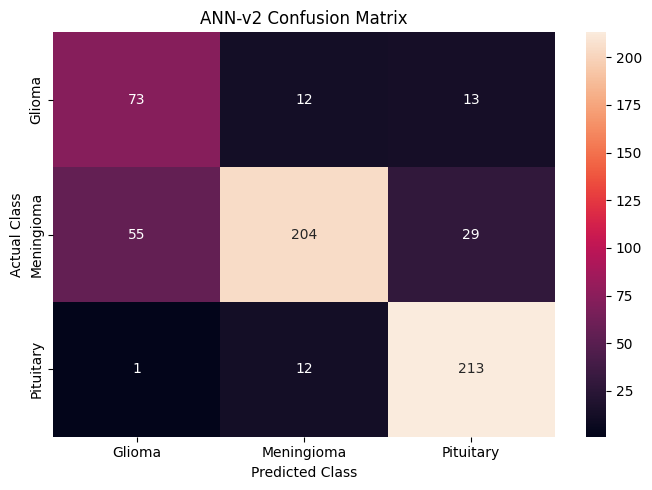

In [47]:
cm_v2 = confusion_matrix(
    y_test_ann,
    y_pred_v2
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v2 Confusion Matrix")

plt.tight_layout()
plt.show()

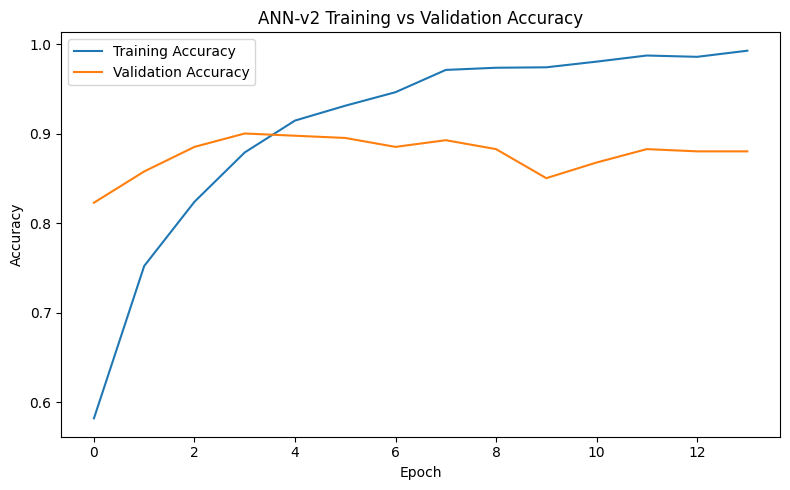

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(
    "ANN-v2 Training vs Validation Accuracy"
)

plt.legend()
plt.tight_layout()
plt.show()

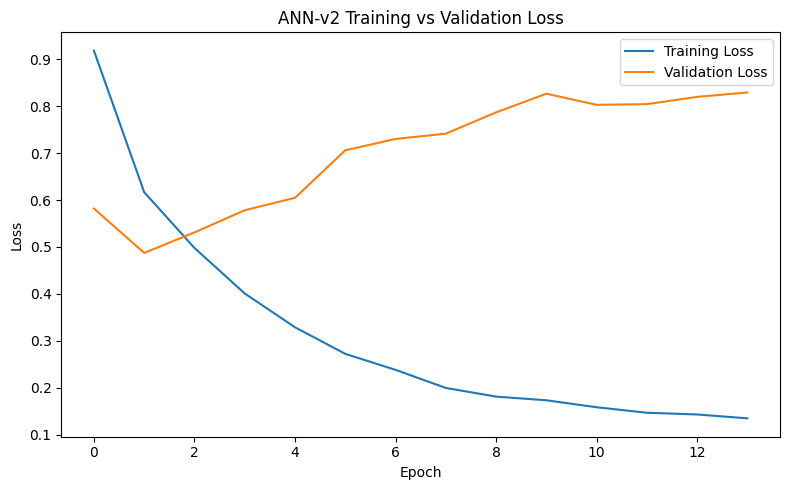

In [49]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "ANN-v2 Training vs Validation Loss"
)

plt.legend()
plt.tight_layout()
plt.show()

In [50]:
ann_v3 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_scaled.shape[1],)
        ),

        layers.Dense(
            256,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.35),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(5e-5)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v3"
)

ann_v3.summary()

Model: "Brain_Tumor_ANN_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,237,699 (16.17 MB)

 Trainable params: 4,236,803 (16.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [51]:
ann_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [61]:
early_stopping_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v3 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v3 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v3.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [62]:
history_v3 = ann_v3.fit(
    X_train_scaled,
    y_train_ann,
    validation_data=(
        X_val_scaled,
        y_val_ann
    ),
    epochs=30,
    batch_size=32,
    class_weight=ann_class_weights,
    callbacks=[
        early_stopping_v3,
        reduce_lr_v3,
        checkpoint_v3
    ],
    verbose=1
)

Epoch 1/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9191 - loss: 0.2669
Epoch 1: val_loss improved from None to 0.44763, saving model to ..\results\best_ann_v3.keras

Epoch 1: finished saving model to ..\results\best_ann_v3.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.9191 - loss: 0.2669 - val_accuracy: 0.8953 - val_loss: 0.4476 - learning_rate: 7.5000e-05
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9405 - loss: 0.2228
Epoch 2: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.

Epoch 2: val_loss did not improve from 0.44763
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9405 - loss: 0.2228 - val_accuracy: 0.8903 - val_loss: 0.4754 - learning_rate: 7.5000e-05
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9508 - loss: 0.1961
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.

Epoch 3: val_loss did not improve from 0.44763
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accurac

In [63]:
best_ann_v3 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v3.keras"
)

test_prob_v3 = best_ann_v3.predict(
    X_test_scaled,
    verbose=0
)

y_pred_v3 = np.argmax(
    test_prob_v3,
    axis=1
)

In [64]:
ann_v3_accuracy = accuracy_score(
    y_test_ann,
    y_pred_v3
)

ann_v3_precision = precision_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_recall = recall_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)

ann_v3_f1 = f1_score(
    y_test_ann,
    y_pred_v3,
    average="macro",
    zero_division=0
)


print("========== ANN-v3 RESULTS ==========")
print(f"Accuracy        : {ann_v3_accuracy:.4f}")
print(f"Macro Precision : {ann_v3_precision:.4f}")
print(f"Macro Recall    : {ann_v3_recall:.4f}")
print(f"Macro F1        : {ann_v3_f1:.4f}")

========== ANN-v3 RESULTS ==========
Accuracy        : 0.8595
Macro Precision : 0.8228
Macro Recall    : 0.8476
Macro F1        : 0.8318


In [65]:
print(
    classification_report(
        y_test_ann,
        y_pred_v3,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.6260    0.7857    0.6968        98
  Meningioma     0.8926    0.8368    0.8638       288
   Pituitary     0.9498    0.9204    0.9348       226

    accuracy                         0.8595       612
   macro avg     0.8228    0.8476    0.8318       612
weighted avg     0.8710    0.8595    0.8633       612



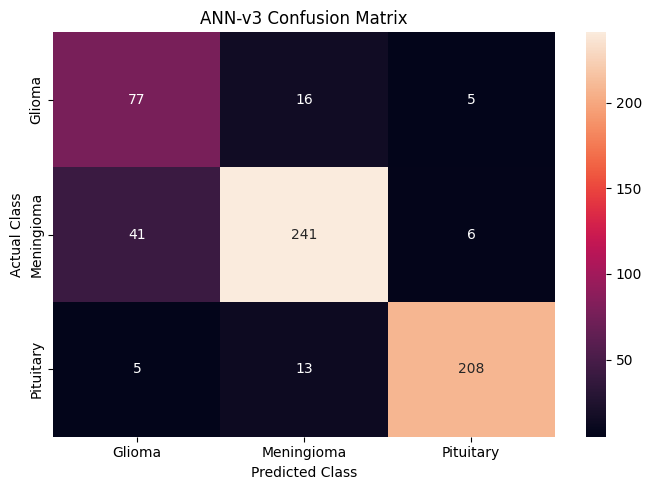

In [66]:
cm_v3 = confusion_matrix(
    y_test_ann,
    y_pred_v3
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ANN-v3 Confusion Matrix")

plt.tight_layout()
plt.show()

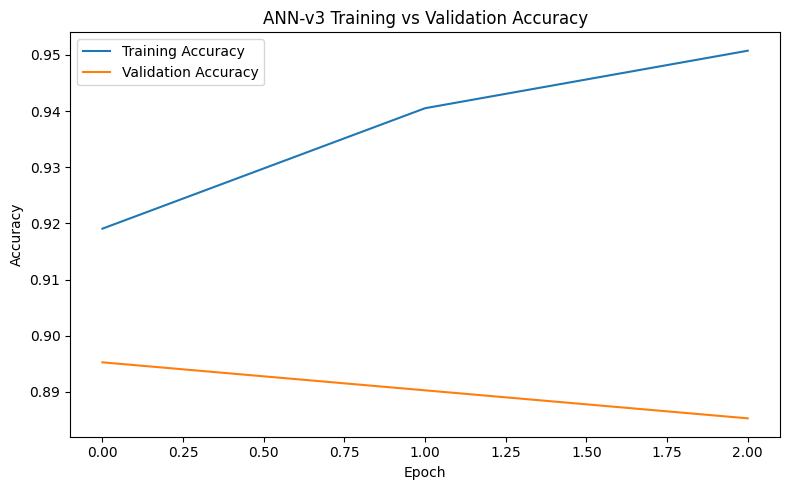

In [67]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v3.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v3 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

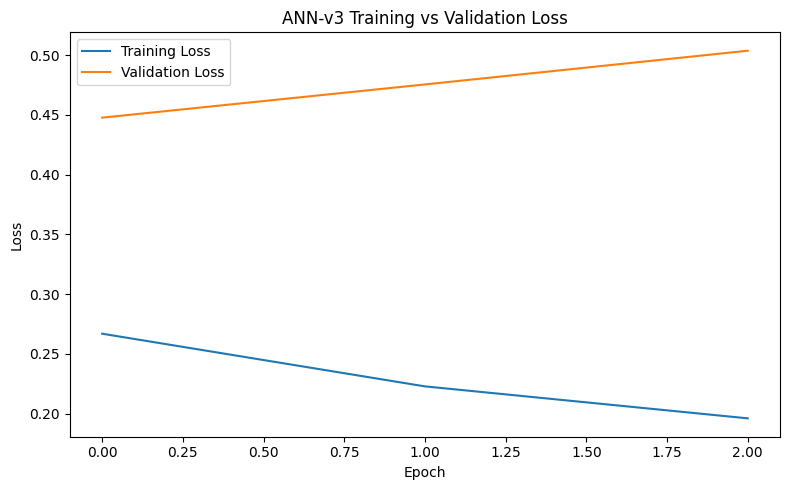

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v3.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v3.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v3 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [69]:
ann_comparison = pd.DataFrame({
    "Model": [
        "ANN-v1",
        "ANN-v2",
        "ANN-v3"
    ],

    "Accuracy": [
        0.8252,
        0.8007,
        ann_v3_accuracy
    ],

    "Macro Precision": [
        0.7896,
        0.7653,
        ann_v3_precision
    ],

    "Macro Recall": [
        0.7826,
        0.7986,
        ann_v3_recall
    ],

    "Macro F1": [
        0.7839,
        0.7732,
        ann_v3_f1
    ]
})

ann_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ANN-v1,0.825200,0.789600,0.782600,0.783900
1,ANN-v2,0.800700,0.765300,0.798600,0.773200
2,ANN-v3,0.859477,0.822794,0.847625,0.831821


In [70]:
augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=0.03,
            fill_mode="nearest"
        ),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="nearest"
        )
    ],
    name="MRI_Augmentation"
)


X_train_aug = np.empty_like(X_train_final)

for i in range(len(X_train_final)):
    image = X_train_final[i][..., np.newaxis]

    augmented = augmentation(
        image,
        training=True
    ).numpy().squeeze()

    X_train_aug[i] = augmented


# Original + augmented training samples
X_train_combined = np.concatenate(
    [
        X_train_final,
        X_train_aug
    ],
    axis=0
)

y_train_combined = np.concatenate(
    [
        y_train_final,
        y_train_final
    ],
    axis=0
)

print("Original training samples :", len(X_train_final))
print("Augmented training samples:", len(X_train_aug))
print("Combined training samples :", len(X_train_combined))

Original training samples : 2051
Augmented training samples: 2051
Combined training samples : 4102


In [71]:
X_train_v4_flat = X_train_combined.reshape(
    X_train_combined.shape[0],
    -1
)

X_val_v4_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

X_test_v4_flat = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)


scaler_v4 = StandardScaler()

X_train_v4_scaled = scaler_v4.fit_transform(
    X_train_v4_flat
)

X_val_v4_scaled = scaler_v4.transform(
    X_val_v4_flat
)

X_test_v4_scaled = scaler_v4.transform(
    X_test_v4_flat
)


print("Train:", X_train_v4_scaled.shape)
print("Validation:", X_val_v4_scaled.shape)
print("Test:", X_test_v4_scaled.shape)

Train: (4102, 16384)
Validation: (401, 16384)
Test: (612, 16384)


In [72]:
y_train_v4 = y_train_combined - 1
y_val_v4 = y_val - 1
y_test_v4 = y_test - 1


classes_v4 = np.unique(y_train_v4)

class_weights_v4 = compute_class_weight(
    class_weight="balanced",
    classes=classes_v4,
    y=y_train_v4
)

ann_v4_class_weights = dict(
    zip(
        classes_v4,
        class_weights_v4
    )
)

print("Class weights:", ann_v4_class_weights)

Class weights: {0: 1.2340553549939832, 1: 0.687793427230047, 2: 1.3591782637508283}


In [73]:
ann_v4 = keras.Sequential(
    [
        keras.Input(
            shape=(X_train_v4_scaled.shape[1],)
        ),

        layers.Dense(
            128,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.30),

        layers.Dense(
            64,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.25),

        layers.Dense(
            32,
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.Activation("relu"),
        layers.Dropout(0.15),

        layers.Dense(
            3,
            activation="softmax"
        )
    ],
    name="Brain_Tumor_ANN_v4"
)

ann_v4.summary()

Model: "Brain_Tumor_ANN_v4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,108,483 (8.04 MB)

 Trainable params: 2,108,099 (8.04 MB)

 Non-trainable params: 384 (1.50 KB)

In [74]:
ann_v4.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=3e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [75]:
early_stopping_v4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_v4 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint_v4 = keras.callbacks.ModelCheckpoint(
    filepath=str(
        RESULTS_ROOT / "best_ann_v4.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [76]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6331 - loss: 0.7840
Epoch 1: val_loss improved from None to 0.45366, saving model to ..\results\best_ann_v4.keras

Epoch 1: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.6331 - loss: 0.7840 - val_accuracy: 0.8404 - val_loss: 0.4537 - learning_rate: 3.0000e-04
Epoch 2/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7396 - loss: 0.5865
Epoch 2: val_loss improved from 0.45366 to 0.39096, saving model to ..\results\best_ann_v4.keras

Epoch 2: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.7396 - loss: 0.5865 - val_accuracy: 0.8579 - val_loss: 0.3910 - learning_rate: 3.0000e-04
Epoch 3/40
127/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7938 - loss: 0.4868
Epoch 3: val_loss improved from 0.39096 to 0.34590, saving model to ..\results\best_ann_v4.keras

Epoch 3: finished saving model

In [77]:
history_v4 = ann_v4.fit(
    X_train_v4_scaled,
    y_train_v4,

    validation_data=(
        X_val_v4_scaled,
        y_val_v4
    ),

    epochs=40,
    batch_size=32,

    class_weight=ann_v4_class_weights,

    callbacks=[
        early_stopping_v4,
        reduce_lr_v4,
        checkpoint_v4
    ],

    verbose=1
)

Epoch 1/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8959 - loss: 0.3015
Epoch 1: val_loss improved from 0.33995 to 0.33564, saving model to ..\results\best_ann_v4.keras

Epoch 1: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.8959 - loss: 0.3015 - val_accuracy: 0.8778 - val_loss: 0.3356 - learning_rate: 7.5000e-05
Epoch 2/40
127/129 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9102 - loss: 0.2712
Epoch 2: val_loss improved from 0.33564 to 0.32759, saving model to ..\results\best_ann_v4.keras

Epoch 2: finished saving model to ..\results\best_ann_v4.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.9098 - loss: 0.2723 - val_accuracy: 0.8728 - val_loss: 0.3276 - learning_rate: 7.5000e-05
Epoch 3/40
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9193 - loss: 0.2519
Epoch 3: val_loss did not improve from 0.32759
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9193 - loss: 0.2519 - 

In [78]:
best_ann_v4 = keras.models.load_model(
    RESULTS_ROOT / "best_ann_v4.keras"
)

test_prob_v4 = best_ann_v4.predict(
    X_test_v4_scaled,
    verbose=0
)

y_pred_v4 = np.argmax(
    test_prob_v4,
    axis=1
)

In [79]:
ann_v4_accuracy = accuracy_score(
    y_test_v4,
    y_pred_v4
)

ann_v4_precision = precision_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_recall = recall_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)

ann_v4_f1 = f1_score(
    y_test_v4,
    y_pred_v4,
    average="macro",
    zero_division=0
)


print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8448
Macro Precision : 0.8036
Macro Recall    : 0.8048
Macro F1        : 0.8040


In [80]:
print(
    classification_report(
        y_test_v4,
        y_pred_v4,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Glioma     0.6176    0.6429    0.6300        98
  Meningioma     0.8527    0.8646    0.8586       288
   Pituitary     0.9404    0.9071    0.9234       226

    accuracy                         0.8448       612
   macro avg     0.8036    0.8048    0.8040       612
weighted avg     0.8475    0.8448    0.8459       612



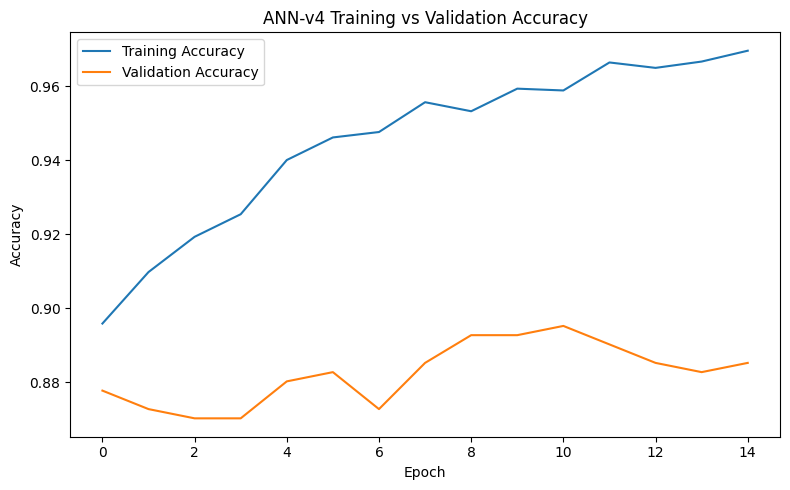

In [81]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_v4.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN-v4 Training vs Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

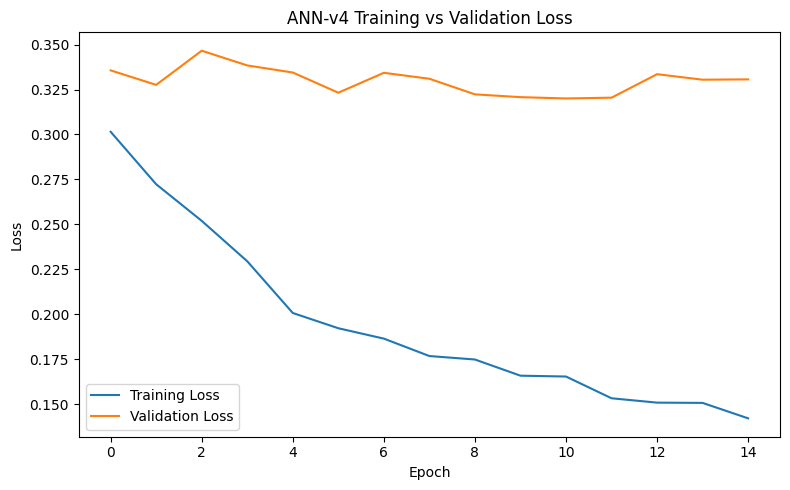

In [82]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_v4.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v4.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN-v4 Training vs Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [83]:
print("========== ANN-v4 RESULTS ==========")
print(f"Accuracy        : {ann_v4_accuracy:.4f}")
print(f"Macro Precision : {ann_v4_precision:.4f}")
print(f"Macro Recall    : {ann_v4_recall:.4f}")
print(f"Macro F1        : {ann_v4_f1:.4f}")

========== ANN-v4 RESULTS ==========
Accuracy        : 0.8448
Macro Precision : 0.8036
Macro Recall    : 0.8048
Macro F1        : 0.8040


In [85]:
## seeing this annv3 is good 
## Now cnn implenataion starts from here
